# Part 1 | Inside the HDF5 file, the power spectrum, and filtering

You will (1) look *inside* the HDF5 file, (2) look at the **raw traces**, (3) use
the **power spectrum** to see what noise is present, (4) **band-pass filter** the
signal to isolate spikes, and (5) measure each electrode's **noise level**.

## Goal

Understand what the raw signal contains and prepare it for spike detection.

By the end of this part you can:
- find your way around an HDF5 file
- plot raw voltage traces and recognise spikes and slow fluctuations in them
- read a power spectrum to see which frequencies (and noise) are in the signal
- band-pass filter the signal to the spike band (300–3000 Hz)
- measure the noise level of every electrode

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 1            # your group number (data exists for groups 1 and 2)
DRUG      = "A"          # config / drug label:  group 1 -> A,B,C,D   group 2 -> A,B
CONDITION = "Baseline"   # "Baseline" or "Drug"

# Path to YOUR group's manifest: the recordings.toml in your group folder on
# the bs-dfs share (the exact path is handed out with the practical), e.g.
#   r"Z:\BEL\Practicals_2026\Group_01\recordings.toml"
MANIFEST  = r"/Volumes/bs-dfs/Temp/BEL/Practicals_2026/Group_01/recordings_mac.toml"

# The manifest stores full paths to the data, so DATA_ROOT is not used here.
# (Leave as ".": it only matters if your manifest uses relative paths.)
DATA_ROOT = "."
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                                                 G01_cfgA_base
GroupID                                                         1
Chip                                                       maxtwo
Drug                                                            A
Conditions                                               Baseline
Well                                                            0
raw_files       /Volumes/bs-dfs/Temp/BEL/Practicals_2026/Group...
sorted_files    /Volumes/bs-dfs/Temp/BEL/Practicals_2026/Group...
Name: 0, dtype: object


## 1. What is an HDF5 file?

Think of it as a **file system inside one file**: **groups** are folders,
**datasets** are the arrays inside them, and both can carry **attributes**
(metadata like sampling rate or gain). Let's walk the tree.

In [2]:
h5_path = mea.raw_path(row, DATA_ROOT)
mea.explore_hdf5(h5_path, max_items=60)

HDF5 file: .//Volumes/bs-dfs/Temp/BEL/Practicals_2026/Group_01/261026/0000/Network/000002/data.raw.h5



FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = './/Volumes/bs-dfs/Temp/BEL/Practicals_2026/Group_01/261026/0000/Network/000002/data.raw.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

> **💬 Discuss:** find the dataset holding the raw voltage
> samples. What is its *shape*? Which dimension is time and which is channels?
> Which attribute gives the sampling rate? You can pull any dataset out with
> `mea.read_hdf5_dataset(h5_path, "<name>")`.

## 2. The raw signal — what does it look like?

Before any analysis, look at the data. The raw signal is the **broadband
voltage** on each electrode, 20,000 samples per second. We plot 2 seconds from
the 8 electrodes with the most online-detected spikes (Part 0), so there is
something to see. Each electrode has its own constant offset, which we remove
(subtract the median) so the traces can be stacked.

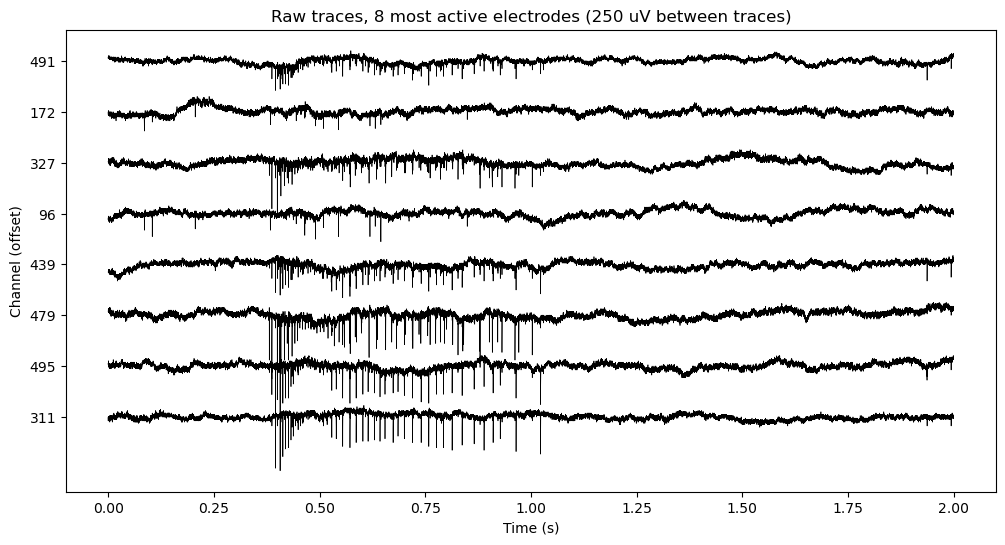

In [3]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
fs = recording.get_sampling_frequency()

# the 8 electrodes with the most online-detected spikes
online = mea.load_online_spikes(row, data_root=DATA_ROOT)
busy = online["channel"].value_counts().index[:8].tolist()

t, raw = mea.get_traces(recording, 0, 2, channel_ids=busy)    # 2 s, 8 channels, uV
raw = raw - np.median(raw, axis=0)                           # remove each offset

fig, ax = plt.subplots(figsize=(12, 6))
mea.plot_traces(t, raw, offset=250, ax=ax, labels=busy)
ax.set_title("Raw traces, 8 most active electrodes (250 uV between traces)"); plt.show()

Zoom in on **50 ms** around the largest spike of the busiest electrode. This
plot is **interactive**: it holds the whole 2 s, but opens on the 50 ms
around the spike.

- **drag a box** to zoom in further (e.g. onto the spike itself),
- **double-click** to zoom out to the full 2 s,
- **hover** over the trace to read time and voltage.

In [4]:
import plotly.graph_objects as go

ch = busy[0]                                                   # busiest electrode
on_ch = online[online["channel"] == ch]
t_online = on_ch.loc[on_ch["amplitude_uv"].idxmin(), "time"]   # its largest online spike

# 2 s of this electrode's raw signal around that spike; pin the exact spike
# time to the deepest point of the raw trough (the online time can be a few ms
# off, depending on the file format)
dur = recording.get_num_frames() / fs
t, raw = mea.get_traces(recording, max(t_online - 1, 0), min(t_online + 1, dur), channel_ids=[ch])
signal = raw[:, 0] - np.median(raw[:, 0])
near = np.abs(t - t_online) <= 0.05
t_spike = t[near][np.argmin(signal[near])]
ms = (t - t_spike) * 1e3                                        # time from the spike (ms)
fig = go.Figure(go.Scatter(x=ms.round(2), y=signal.round(1), mode="lines",
                           line=dict(color="black", width=1)))
fig.update_layout(title=f"Electrode {ch}: raw signal (opens on 50 ms; drag to zoom)",
                  xaxis_title="Time from the spike (ms)", yaxis_title="uV",
                  xaxis_range=[-25, 25], height=350, template="simple_white")
fig.show()

> **💬 Discuss:** in the raw traces, find (1) **slow** wandering of the
> baseline and (2) **fast**, sharp downward deflections. Which one is a spike?
> How long does one spike last (zoom plot), and how large is it compared with
> the wiggles between spikes? Are there moments when **many electrodes spike
> together**? The next sections separate these components by frequency.

## 3. The power spectrum — what dominant frequencies are in the signal?

The **power spectrum** shows how much signal sits at each frequency. In the raw
signal of an HD-MEA, look for:

- **slow** components (below ~10 Hz): baseline drift and local field potentials,
  usually the most power;
- **line noise**: narrow peaks at the mains frequency (**50 Hz** in Europe,
  60 Hz in the Americas) and its multiples — *only if* the setup picks up mains
  interference. Many recordings have none;
- the **spike band** (~300–3000 Hz): broad, low power, but that's where the
  action potentials are.

### Worked example — plot the spectrum of one electrode

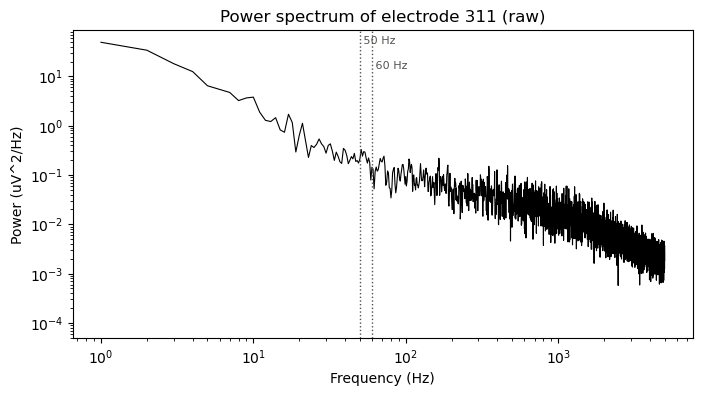

In [5]:
ch = busy[0]                                                   # busiest electrode (section 2)
t, raw = mea.get_traces(recording, 0, 5, channel_ids=[ch])     # 5 s, 1 channel
trace = raw[:, 0]

mea.plot_power_spectrum(trace, fs, flim=(1, 5000), mark_hz=(50, 60))
plt.title(f"Power spectrum of electrode {ch} (raw)"); plt.show()

### ✎ Your turn — is there line noise in your recording?

Line noise is a **narrow** peak: the power at 50 Hz is far above the power at
the frequencies right next to it. Without line noise, 50 Hz looks just like its
neighbours. So compare the power at 50 Hz with the **typical** (median) power
between 40 and 60 Hz.

In [6]:
f, power = mea.power_spectrum(trace, fs)
at_50  = power[np.argmin(np.abs(f - 50))]        # power in the 50 Hz bin
around = power[(f >= 40) & (f <= 60)]            # its neighbourhood, 40-60 Hz

# TODO: compare with the TYPICAL neighbour: use np.median instead of np.max.
ratio = at_50 / np.max(around)
print(f"power at 50 Hz is {ratio:.1f} x the typical power around it")

mea.check(ratio, mea.line_noise_ratio(f, power, f0=50),
          hint="ratio = at_50 / np.median(around)")

power at 50 Hz is 0.6 x the typical power around it
[X] not quite yet.
   hint: ratio = at_50 / np.median(around)
   you got: 0.6357515174094683
   expected ~ 0.9876167302365526


False

> **💬 Discuss:** is there line noise in your recording? Check 60 Hz too
> (`mea.line_noise_ratio(f, power, f0=60)`) and another electrode, e.g.
> `busy[3]`. If there is none, what could keep mains interference out of an
> HD-MEA recording?
>
> A ratio near **1** means no line-noise peak; **~10 or more** means a clear one.

## 4. Filtering  (pipeline step 1)

To isolate **action potentials** we band-pass filter to ~**300–3000 Hz**,
removing slow drift/LFP (< 300 Hz) and high-frequency noise. The helper uses a
zero-phase filter, so spike times are not shifted.

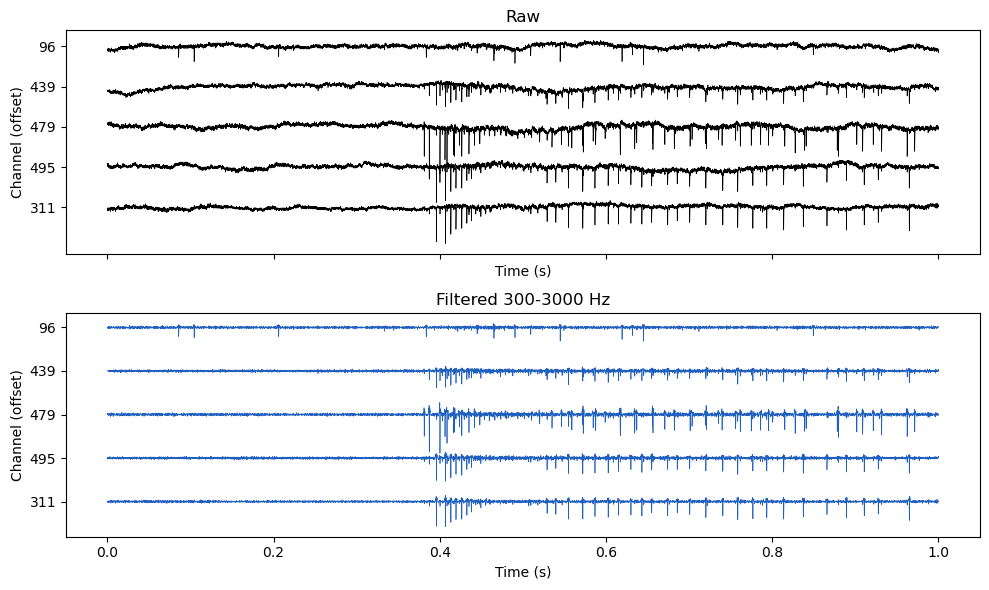

In [7]:
t, raw = mea.get_traces(recording, 0, 1, channel_ids=busy[:5])
filt = mea.bandpass_filter(raw, fs, low=300, high=3000)
raw = raw - np.median(raw, axis=0)                             # stack around 0

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
mea.plot_traces(t, raw,  offset=300, ax=ax[0], labels=busy[:5]); ax[0].set_title("Raw")
mea.plot_traces(t, filt, offset=300, ax=ax[1], labels=busy[:5], color="#1f5fbf"); ax[1].set_title("Filtered 300-3000 Hz")
plt.tight_layout(); plt.show()

### What filtering does to a spike

Back to the 50 ms around the largest spike from section 2, now raw (black) and
filtered (blue) on the same axes, with a zoom on the spike itself (right). We
filter 1 s around the spike and then cut out the 50 ms, so the filter's
start-up at the edges doesn't show.

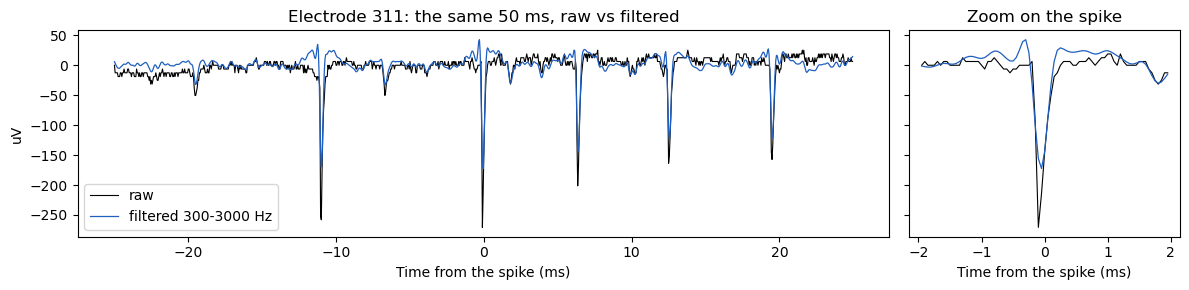

In [8]:
t, x = mea.get_traces(recording, t_spike - 0.5, t_spike + 0.5, channel_ids=[ch])
x_filt = mea.bandpass_filter(x[:, 0], fs)
x_raw = x[:, 0] - np.median(x[:, 0])
ms = (t - t_spike) * 1e3                                          # time from the spike (ms)

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True, width_ratios=[3, 1])
for a, half in zip(ax, [25, 2]):                                  # 50 ms, and a 4 ms zoom
    win = np.abs(ms) <= half
    a.plot(ms[win], x_raw[win], color="black", lw=0.8, label="raw")
    a.plot(ms[win], x_filt[win], color="#1f5fbf", lw=0.9, label="filtered 300-3000 Hz")
    a.set_xlabel("Time from the spike (ms)")
ax[0].set_ylabel("uV"); ax[0].legend(loc="lower left")
ax[0].set_title(f"Electrode {ch}: the same 50 ms, raw vs filtered"); ax[1].set_title("Zoom on the spike")
plt.tight_layout(); plt.show()

> **💬 Discuss:** the baseline is now flat around 0, but did the spikes
> keep their shape? Compare the **depth of the trough**: the filter makes it
> shallower, because cutting above 3000 Hz smooths its sharp tip. Then look
> just before and after the trough: cutting below 300 Hz adds small
> **positive lobes**. Keep this in mind in Part 4: the waveforms and amplitudes
> you measure there are *filtered* ones.

### ✎ Your turn — does the filter remove the low frequencies?

Filter `trace` (your 5-second electrode from above) and compare its spectrum
**before** (left) and **after** (right) filtering. Everything below 300 Hz —
drift, local field potentials and any line noise — should drop away, while the
spike band (300–3000 Hz, between the dotted lines) stays the same.
Note that the cut-off is a **slope, not a wall**: far below 300 Hz the power
practically vanishes, but just below 300 Hz it is only reduced (about 10x at
200–300 Hz), not removed.

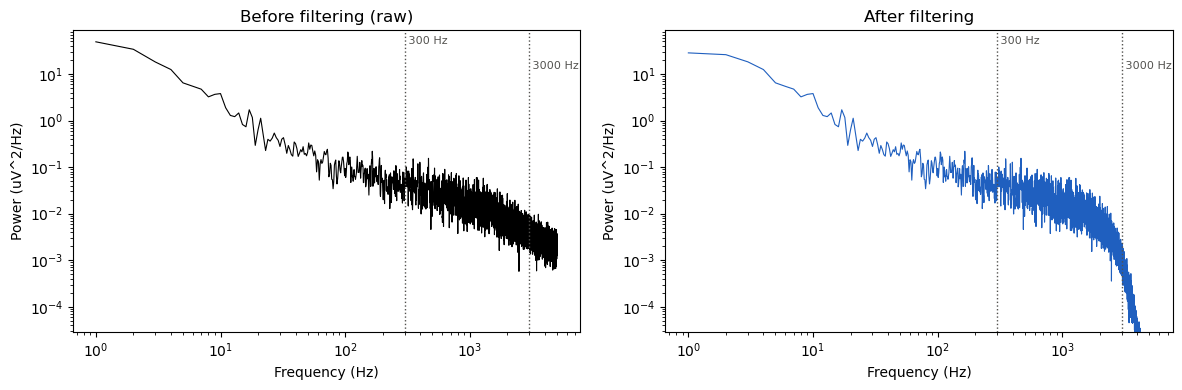

Low cut-off you used should be 300 Hz.


In [9]:
# TODO: change the lower cut-off from 1 Hz to 300 Hz, to remove drift, LFP and line noise.
trace_filt = mea.bandpass_filter(trace, fs, low=1, high=3000)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
mea.plot_power_spectrum(trace,      fs, ax=ax[0], mark_hz=(300, 3000)); ax[0].set_title("Before filtering (raw)")
mea.plot_power_spectrum(trace_filt, fs, ax=ax[1], mark_hz=(300, 3000), color="#1f5fbf"); ax[1].set_title("After filtering")
ax[1].tick_params(labelleft=True)                # same scale, but numbers on both
plt.tight_layout(); plt.show()
print("Low cut-off you used should be 300 Hz.")

## 5. Noise level per electrode — before detecting spikes

In Part 2 a spike is a dip below **−5 × the noise level** of its electrode. So
before detecting anything, check how noisy the electrodes are. After filtering
to the spike band, the signal is mostly noise, so its **RMS** (root mean square,
$\sqrt{\text{mean}(x^2)}$) is a good measure of each electrode's noise. We
compute it for **every** electrode over 2 s and look at the distribution.

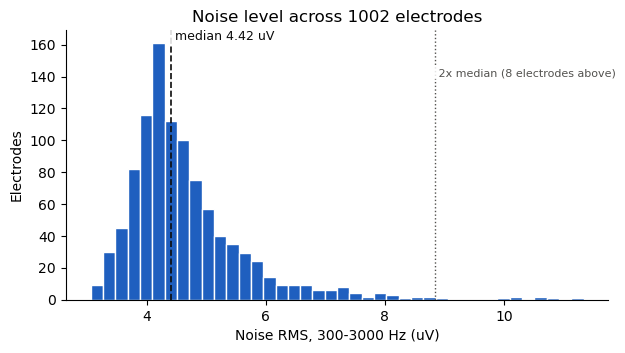

In [10]:
rms = mea.channel_rms(recording, t_start=0, duration=2.0)   # uV, one value per electrode

mea.plot_rms_distribution(rms)
plt.title(f"Noise level across {len(rms)} electrodes"); plt.show()

> **💬 Discuss:** what is a typical noise level, in uV? With a 5x
> threshold, how large must a spike be to be detected on a typical electrode,
> and on the noisiest ones? Electrodes far above the rest (beyond 2x the median)
> may be poorly coupled to the cells or picking up interference. Would you
> trust spikes detected there?

> **One catch, for Part 2:** The RMS averages *everything* in the window —
> including the spikes. On a quiet electrode that hardly matters. But on a busy
> one, the large spikes inflate the RMS, so a threshold of 5 x RMS would be set
> too high, exactly where there are the most spikes to find. Part 2 uses a noise
> estimate that ignores the spikes.